# Análise Exploratória - Dados NPS

## 1. Importação das bibliotecas

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1.1 Definindo identidade visual

In [67]:
AZUL = "#17365D"
VERDE = "#26A69A"
CINZA = "#65758B"

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=[AZUL, VERDE]
)

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "grid.alpha": 0.2,
    "axes.spines.top": False,
    "axes.spines.right": False
})

## 2. Carregamento e estrutura dos dados

In [31]:
dados = pd.read_csv("../data/raw/desafio_nps_fase_1.csv")

In [32]:
dados.head(10)

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9
5,6,35,Sudeste,75,50006,568.76,6,36.58,3,4,5,41.82,2,2,3,0.9,0,5,1.5
6,7,37,Sudeste,68,50007,41.29,3,99.62,6,8,3,35.83,3,3,4,1.4,0,6,0.6
7,8,60,Sul,37,50008,428.76,4,29.54,10,11,5,44.50,1,0,2,0.0,0,2,4.1
8,9,40,Sul,60,50009,121.56,3,91.95,6,6,3,24.88,2,1,9,6.2,0,3,0.8
9,10,51,Sudeste,70,50010,411.01,6,37.47,3,9,2,30.59,1,0,7,2.7,0,2,4.2


In [33]:
print(f"O conjunto de dados possui {dados.shape[0]} linhas e {dados.shape[1]} colunas")

O conjunto de dados possui 2500 linhas e 19 colunas


In [34]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   str    
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64  
 14  res

## 3. Qualidade dos dados

### 3.1 Valores ausentes e vazios

In [35]:
dados.isnull().sum()

customer_id                  0
customer_age                 0
customer_region              0
customer_tenure_months       0
order_id                     0
order_value                  0
items_quantity               0
discount_value               0
payment_installments         0
delivery_time_days           0
delivery_delay_days          0
freight_value                0
delivery_attempts            0
customer_service_contacts    0
resolution_time_days         0
nps_score                    0
repeat_purchase_30d          0
complaints_count             0
csat_internal_score          0
dtype: int64

In [36]:
print("Valores nulos:", dados.isna().sum().sum())

# Valores vazios, espaços em branco ou textos que indicam ausência de informação na coluna customer_region
marcadores = ["", "na", "n/a", "null", "none", "nan"]

print("Valores vazios ou ausentes em texto:",
      dados["customer_region"].str.strip().str.lower().isin(marcadores).sum())

Valores nulos: 0
Valores vazios ou ausentes em texto: 0


### 3.2 Registros duplicados

In [37]:
print("Linhas duplicadas:", dados.duplicated().sum())

print("Pedidos duplicados:", dados["order_id"].duplicated().sum())

Linhas duplicadas: 0
Pedidos duplicados: 0


### 3.3 Consistência e limites dos valores

In [38]:
# Verificando se existe valores fora do range esperado
print("NPS inválido:", ((dados["nps_score"] < 0) | (dados["nps_score"] > 10)).sum())

print("Idade inválida:", (dados["customer_age"] <= 0).sum())

print("Tempo de relacionamento negativo:", (dados["customer_tenure_months"] < 0).sum())

print("Valor do pedido inválido:", (dados["order_value"] < 0).sum())

print("Quantidade de itens inválida:", (dados["items_quantity"] <= 0).sum())

print("Desconto negativo:", (dados["discount_value"] < 0).sum())

print("Tempo de entrega negativo:", (dados["delivery_time_days"] < 0).sum())

print("Atraso negativo:", (dados["delivery_delay_days"] < 0).sum())

print("Quantidade de reclamações negativa:", (dados["complaints_count"] < 0).sum())

print("Frete negativo:", (dados["freight_value"] < 0).sum())

print("Parcelas inválidas:", (dados["payment_installments"] < 1).sum())

print("Tentativas de entrega inválidas:", (dados["delivery_attempts"] < 1).sum())

print("Contatos negativos:", (dados["customer_service_contacts"] < 0).sum())

print("Tempo de resolução negativo:", (dados["resolution_time_days"] < 0).sum())

print("Recompra inválida:", ((dados["repeat_purchase_30d"] != 0) & (dados["repeat_purchase_30d"] != 1)).sum())

NPS inválido: 0
Idade inválida: 0
Tempo de relacionamento negativo: 0
Valor do pedido inválido: 0
Quantidade de itens inválida: 0
Desconto negativo: 0
Tempo de entrega negativo: 0
Atraso negativo: 0
Quantidade de reclamações negativa: 0
Frete negativo: 0
Parcelas inválidas: 0
Tentativas de entrega inválidas: 0
Contatos negativos: 0
Tempo de resolução negativo: 0
Recompra inválida: 0


In [46]:
# Verificação de notas de NPS com casas decimais
nps_com_decimais = (dados["nps_score"] % 1 != 0).sum()

print(f"NPS com valores decimais:{nps_com_decimais}")

print(f"Percentual de NPS com valores decimais: {nps_com_decimais / len(dados) * 100:.2f}%")

NPS com valores decimais:2075
Percentual de NPS com valores decimais: 83.00%


### 3.4 Validação das categorias

In [43]:
dados["customer_region"].value_counts()

customer_region
Sul             521
Sudeste         520
Norte           506
Nordeste        485
Centro-Oeste    468
Name: count, dtype: int64

### Resumo - Qualidade dos dados

A base contém 2.500 registros e 19 variáveis.

Nas verificações, não foram encontrados valores nulos, textos indicando ausência de informação ou registros duplicados.

As variáveis numéricas estão dentro dos limites básicos definidos, e as cinco regiões brasileiras estão representadas corretamente.

Considerando essas validações, não foi necessário realizar nenhum tratamento nos dados nesta etapa.

**Observação:** Tradicionalmente, o NPS é coletado por meio de notas inteiras de 0 a 10. Entretanto, como 83% dos registros apresentam notas decimais, seguiremos com a análise preservando os valores originais, considerando essa característica como uma limitação da base, já que o enunciado não esclarece a origem dessas notas.

## 4. Estatística descritiva

In [ ]:

dados.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,2500.0,1250.500000,721.832160,1.00,625.7500,1250.500,1875.2500,2500.00
customer_age,2500.0,43.396000,14.888487,18.00,31.0000,43.000,56.0000,69.00
customer_tenure_months,2500.0,61.322400,34.478729,1.00,31.0000,62.000,91.0000,119.00
order_id,2500.0,51250.500000,721.832160,50001.00,50625.7500,51250.500,51875.2500,52500.00
order_value,2500.0,434.259740,289.772497,7.76,220.2450,375.515,577.2900,1983.81
items_quantity,2500.0,3.470800,1.687331,1.00,2.0000,3.000,5.0000,6.00
discount_value,2500.0,29.745620,29.225603,0.02,8.8850,20.935,40.8325,230.33
payment_installments,2500.0,6.004000,3.159743,1.00,3.0000,6.000,9.0000,11.00
delivery_time_days,2500.0,8.022000,3.770411,2.00,5.0000,8.000,11.0000,14.00
delivery_delay_days,2500.0,2.187200,1.454442,0.00,1.0000,2.000,3.0000,8.00


A análise não apresentou valores mínimos ou máximos claramente incompatíveis com o contexto dos dados.

Alguns indicadores chamaram a atenção:

- A nota média de satisfação é de 4,38, indicando avaliações relativamente baixas.
- A recompra em até 30 dias permanece em zero (sem recompra) até o 3º quartil.
- A quantidade média de reclamações é de 4,15 por registro.
- O atraso médio nas entregas é de 2,19 dias, com pelo menos 75% dos registros apresentando atrasos de 1 dia ou mais.

## 5. Análise da satisfação dos clientes

### 5.1 Distribuição das notas
Como estão distribuídas as notas de NPS dos clientes? 

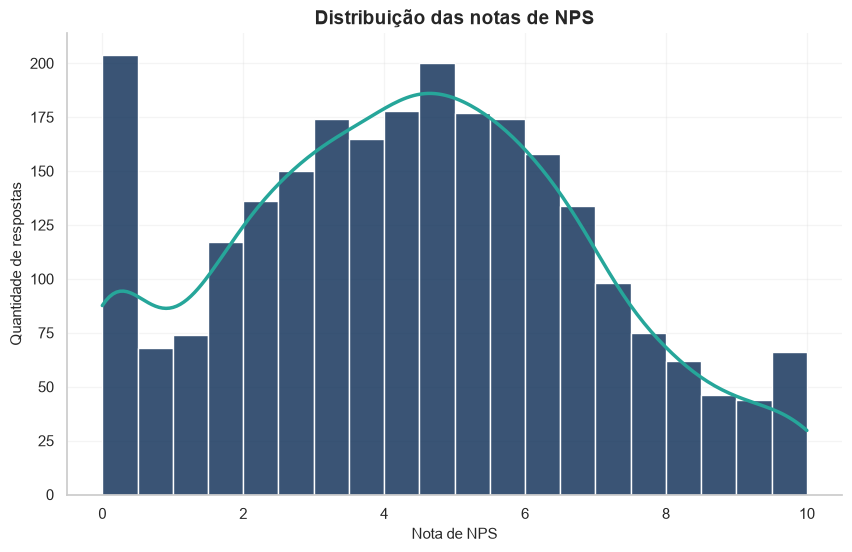

In [71]:
plt.figure(figsize=(10,6))

ax = sns.histplot(
    data=dados,
    x="nps_score",
    bins=20,
    kde=True,
    color=AZUL,
    edgecolor="white",
    alpha=0.85,
    line_kws={"linewidth": 2.5}
)

ax.lines[0].set_color(VERDE)

plt.title("Distribuição das notas de NPS")
plt.xlabel("Nota de NPS")
plt.ylabel("Quantidade de respostas")

plt.show()